In [61]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [62]:
from pathlib import Path
import sys

import torch
from scipy.special import logit

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.config import DataConfig, AlgorithmConfig
from experiments.experiments import (
    MonteCarloConfig,
    run_monte_carlo_experiment,
    plot_monte_carlo_experiment,
)

torch.set_default_dtype(torch.float64)

In [63]:
config = MonteCarloConfig(
    data=DataConfig(
        scale=1.0,
        label_prior=0.2,
        supervision_ratio=0.1,
        data_to_dimension_ratio=8.0,
        signal_law=lambda: torch.randn(1).item(),
    ),
    algorithm=AlgorithmConfig(
        n_iterations=300,
        positive_margin=logit(0.8),
        negative_margin=-logit(0.8),
        step_size=0.1,
        pseudo_label_param=5.0,
        penalty_param=0.1,
    ),
    d=2_000,
    seed=42,
    k=10_000,
    runs=20,
)

In [64]:
results = run_monte_carlo_experiment(config)

Running seed 42...
Running seed 43...
Running seed 44...
Running seed 45...
Running seed 46...
Running seed 47...
Running seed 48...
Running seed 49...
Running seed 50...
Running seed 51...
Running seed 52...
Running seed 53...
Running seed 54...
Running seed 55...
Running seed 56...
Running seed 57...
Running seed 58...
Running seed 59...
Running seed 60...
Running seed 61...


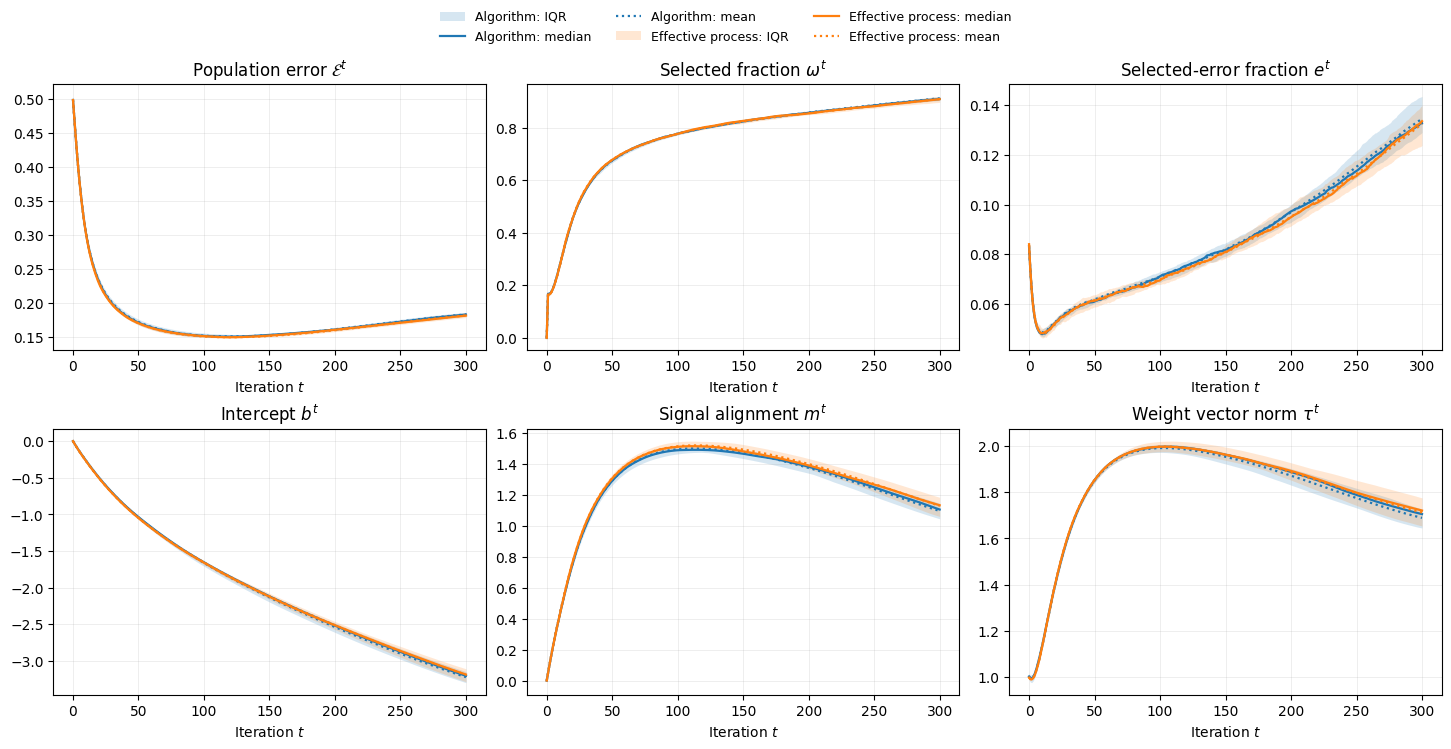

In [66]:
fig, axes = plot_monte_carlo_experiment(
    results, metrics=[
        "population_error","unl_usage", "unl_selected_error",
        "bias_term", "weight_signal_alignment", "weight_vector_norm"
    ],
    save_image=True,
    image_path=project_root / "outputs" / "figures" / "approximation_accuracy.png",
)

# Export vector artwork with fonts sized for the manuscript's full text width.
font_size = 8.0 * fig.get_figwidth() / 6.27
for ax in fig.axes:
    ax.title.set_fontsize(font_size)
    ax.xaxis.label.set_fontsize(font_size)
    ax.yaxis.label.set_fontsize(font_size)
    ax.tick_params(axis="both", labelsize=font_size)
for legend in fig.legends:
    for text in legend.get_texts():
        text.set_fontsize(font_size)
fig.savefig(
    project_root / "manuscript" / "figures" / "approximation_accuracy.pdf",
    bbox_inches="tight",
)
